# DDPM Architecture and Conditioning

This CPU-only notebook explains the fixed linear DDPM, epsilon prediction, native32/native64 U-Nets, and scratch text conditioning.  It does not load checkpoints onto GPU or generate images.

## Objective

For $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$, the denoiser learns $\epsilon_\theta(x_t,t,c)$ with mean-squared error.  Unconditional endpoints omit $c$ completely; conditional endpoints use a TRAIN-derived tokenizer and cross-attention.

In [1]:
from pathlib import Path
import json
ROOT=Path.cwd().resolve()
while not (ROOT/'src').exists() and ROOT.parent!=ROOT: ROOT=ROOT.parent
models=json.loads((ROOT/'src/tiny_avatar_diffusion/public_model_manifest.json').read_text())['models']
for model in models:
    print(model['display_name'], f"{model['parameters']:,}")
print('Fixed DDPM contract: epsilon prediction; 1,000-step ancestral sampling; no live sampling in this notebook.')

DDPM-U32 â€” native 32, EMA 40k 4,595,779
DDPM-C32 â€” native 32, EMA 40k 4,749,059
DDPM-U64 â€” native 64, EMA 60k 5,077,123
DDPM-C64 â€” native 64, EMA 60k 5,230,403
Fixed DDPM contract: epsilon prediction; 1,000-step ancestral sampling; no live sampling in this notebook.


## Final public family

| endpoint | native resolution | conditioning | identity |
|---|---:|---|---|
| DDPM-U32 | 32 | none | TinyUNet |
| DDPM-C32 | 32 | CA8+CA16 | conditional U-Net |
| DDPM-U64 | 64 | none | native64 image path only |
| DDPM-C64 | 64 | CA8+CA16 | native64 conditional U-Net |

CA8 is bottleneck attention and CA16 is decoder attention. The native64 extension is not a pure resolution intervention: capacity and preprocessing also change.

## Reproducibility boundary

Architecture source: `src/tiny_avatar_diffusion/unet.py`, `text_conditioning.py`, `v2_native64.py`, and `v2a_unconditional_native64.py`. Live sampling is deliberately excluded. The four-model Streamlit UI has separate M4.9 GPU validation.

## 1. DDPM objective and the fixed 1,000-step process

For a clean normalized image $x_0$ and $t \in \{0,\ldots,999\}$, the implemented linear schedule constructs $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$, with $\epsilon\sim\mathcal{N}(0,I)$. The U-Net is trained to predict that noise: $\mathcal{L}=\mathbb{E}\lVert\epsilon-\epsilon_\theta(x_t,t,c)\rVert_2^2$. For unconditional models $c$ is absent.

At inference, the repository starts from Gaussian $x_T$ and applies the ancestral reverse transition from $t=999$ to $0$. The predicted noise determines $\hat{x}_0$ and the posterior mean; Gaussian noise is added only when $t>0$. This notebook inspects those operations but deliberately does **not** call the sampling loop.

linear beta range: 0.0001 to 0.02; q_sample shape: (1, 3, 32, 32)


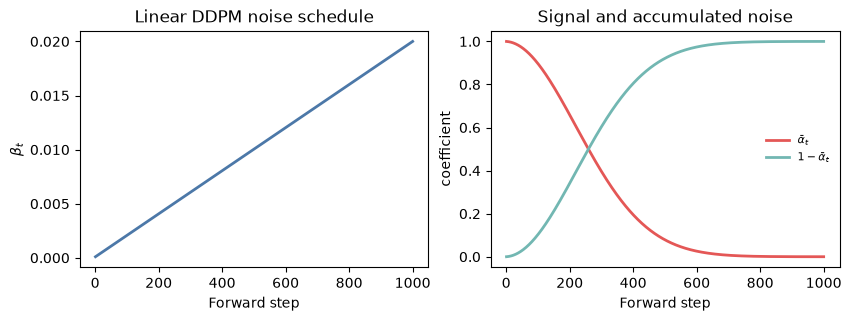

In [2]:
import torch
import matplotlib.pyplot as plt
from tiny_avatar_diffusion.diffusion import LinearDDPMSchedule

schedule = LinearDDPMSchedule(num_timesteps=1_000)
x0 = torch.zeros(1, 3, 32, 32)
epsilon = torch.randn(x0.shape, generator=torch.Generator().manual_seed(2026), dtype=x0.dtype)
timesteps = torch.tensor([500], dtype=torch.long)
xt = schedule.q_sample(x0, timesteps, epsilon)
assert xt.shape == x0.shape and schedule.betas.numel() == 1_000
print(f'linear beta range: {schedule.betas[0]:.4g} to {schedule.betas[-1]:.3g}; q_sample shape: {tuple(xt.shape)}')

FIGURE_DIR = ROOT / 'docs' / 'report' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.1), constrained_layout=True)
steps = torch.arange(1, 1001)
axes[0].plot(steps, schedule.betas, color='#4C78A8', lw=2)
axes[0].set(title='Linear DDPM noise schedule', xlabel='Forward step', ylabel=r'$\beta_t$')
axes[1].plot(steps, schedule.alphas_cumprod, color='#E45756', lw=2, label=r'$\bar\alpha_t$')
axes[1].plot(steps, 1 - schedule.alphas_cumprod, color='#72B7B2', lw=2, label=r'$1-\bar\alpha_t$')
axes[1].set(title='Signal and accumulated noise', xlabel='Forward step', ylabel='coefficient')
axes[1].legend(frameon=False, fontsize=8)
for suffix in ('png', 'pdf'):
    fig.savefig(FIGURE_DIR / f'ddpm_linear_schedule.{suffix}', dpi=220 if suffix == 'png' else None, bbox_inches='tight')
plt.show()


## 2. Implemented U-Nets: image path, time, and skips

The native-32 backbone is a 32 → 16 → 8 encoder and 8 → 16 → 32 decoder. Each level uses time-conditioned residual blocks: GroupNorm → SiLU → convolution, an additive projection of a 256-dimensional timestep embedding, then a second normalized convolution and residual shortcut. Timesteps use fixed 64-dimensional sinusoidal features followed by a 64 → 256 → 256 MLP. Encoder activations are concatenated into the corresponding decoder level as skip connections.

The native-64 models add a symmetric outer 64 → 32 stage and the matching 32 → 64 decoder stage. Therefore native-64 is an authentic architecture with a larger image path, rather than an upsampled native-32 model.

In [3]:
from tiny_avatar_diffusion.unet import TinyUNet, ConditionalTinyUNet
from tiny_avatar_diffusion.text_conditioning import TextConditioningEncoder
from tiny_avatar_diffusion.v2a_unconditional_native64 import V2AUnconditionalNative64UNet
from tiny_avatar_diffusion.v2_native64 import make_v2_model

text_encoder = TextConditioningEncoder().eval()
models_by_id = {
    'DDPM-U32': TinyUNet().eval(),
    'DDPM-C32': ConditionalTinyUNet(use_decoder16_cross_attention=True).eval(),
    'DDPM-U64': V2AUnconditionalNative64UNet().eval(),
    'DDPM-C64': make_v2_model('v2_a')[1].eval(),
}
input_ids = torch.tensor([[1, 4, 21, 29, 44, 2, 0]], dtype=torch.long)
mask = torch.tensor([[1, 1, 1, 1, 1, 1, 0]], dtype=torch.long)
context = text_encoder(input_ids, mask)
observed = {}
for model_id, model in models_by_id.items():
    resolution = 64 if model_id.endswith('64') else 32
    x_t = torch.zeros(1, 3, resolution, resolution)
    t = torch.tensor([999], dtype=torch.long)
    with torch.no_grad():
        prediction = model(x_t, t, context, mask) if '-C' in model_id else model(x_t, t)
    denoiser_parameters = sum(p.numel() for p in model.parameters())
    total_parameters = denoiser_parameters + (sum(p.numel() for p in text_encoder.parameters()) if '-C' in model_id else 0)
    observed[model_id] = (tuple(prediction.shape), denoiser_parameters, total_parameters)
    assert total_parameters == next(item['parameters'] for item in models if item['id'] == model_id)
print('Text encoder context shape:', tuple(context.shape), '; parameters:', sum(p.numel() for p in text_encoder.parameters()))
for model_id, (shape, denoiser_parameters, total_parameters) in observed.items():
    print(f'{model_id}: epsilon={shape}; denoiser={denoiser_parameters:,}; published total={total_parameters:,}')


Text encoder context shape: (1, 7, 64) ; parameters: 102976
DDPM-U32: epsilon=(1, 3, 32, 32); denoiser=4,595,779; published total=4,595,779
DDPM-C32: epsilon=(1, 3, 32, 32); denoiser=4,646,083; published total=4,749,059
DDPM-U64: epsilon=(1, 3, 64, 64); denoiser=5,077,123; published total=5,077,123
DDPM-C64: epsilon=(1, 3, 64, 64); denoiser=5,127,427; published total=5,230,403


## 3. Scratch text conditioning and cross-attention

Conditional models use the DR01 train-only 45-token vocabulary. The scratch-trained Transformer has token embeddings and fixed positional encodings, two pre-LayerNorm non-causal self-attention blocks (4 heads, model width 64, FFN width 256), and a final LayerNorm. It returns a `[batch, 7, 64]` context sequence.

CA8 applies image-query/text-key-value cross-attention at the 8×8 bottleneck. CA16 adds the same operation at the decoder 16×16 feature map. The final public C32 and C64 architectures use both CA8 and CA16. Attention masks retain the DR01 convention (1 valid, 0 padding), so padding cannot be used as a text key or value.

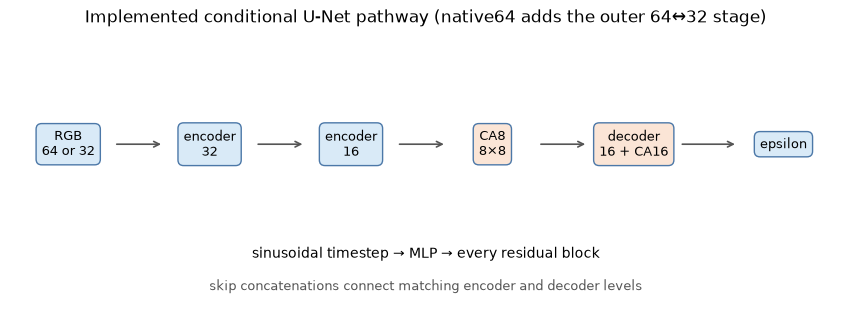

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 3.0), constrained_layout=True)
ax.axis('off')
stages = [('RGB\n64 or 32', 0.07), ('encoder\n32', 0.24), ('encoder\n16', 0.41), ('CA8\n8×8', 0.58), ('decoder\n16 + CA16', 0.75), ('epsilon', 0.93)]
for label, x in stages:
    color = '#FBE5D6' if 'CA' in label else '#D9EAF7'
    ax.text(x, 0.58, label, ha='center', va='center', fontsize=9, bbox={'boxstyle':'round,pad=0.45', 'facecolor':color, 'edgecolor':'#4C78A8'})
for (_, x0), (_, x1) in zip(stages, stages[1:]):
    ax.annotate('', xy=(x1 - 0.055, 0.58), xytext=(x0 + 0.055, 0.58), arrowprops={'arrowstyle':'->', 'lw':1.2, 'color':'#555555'})
ax.annotate('sinusoidal timestep → MLP → every residual block', xy=(0.50, 0.16), ha='center', fontsize=10)
ax.annotate('skip concatenations connect matching encoder and decoder levels', xy=(0.50, 0.04), ha='center', fontsize=9, color='#555555')
ax.set_title('Implemented conditional U-Net pathway (native64 adds the outer 64↔32 stage)')
for suffix in ('png', 'pdf'):
    fig.savefig(FIGURE_DIR / f'ddpm_architecture_pathway.{suffix}', dpi=220 if suffix == 'png' else None, bbox_inches='tight')
plt.show()


## 4. Training, EMA, checkpoints, and authenticated continuations

The notebook does not train. The recorded conditional protocol uses AMP FP16, physical batch 32, gradient accumulation 1, learning rate $2\times10^{-4}$, linear 1,000-step diffusion, and EMA decay 0.9999. A *successful optimizer update* is counted only after finite gradients have passed the AMP/GradScaler path; EMA is updated at that point. Checkpoints preserve model/EMA states and the continuation runners bind optimizer, GradScaler, RNG, sampler/progress, and identity metadata so that a documented continuation can be validated rather than assumed.

The public endpoints are inference EMA weights. Historical RAW states and continuation internals remain provenance assets, not professor-facing inference inputs. The C64 release manifest records its authenticated source checkpoint; the cell below reads the small configuration-manifest bindings without loading checkpoint tensors and reports their current hash status.

In [5]:
from tiny_avatar_diffusion.ca16_experiment import CA16RunSpec, ArchitectureArm

spec = CA16RunSpec(ArchitectureArm.CA8_CA16, 2026)
protocol = spec.frozen_protocol
assert protocol['diffusion_timesteps'] == 1_000 and protocol['ema_decay'] == 0.9999
import hashlib
manifest_status = []
for reference in spec.manifests:
    path = ROOT / reference.path
    actual = hashlib.sha256(path.read_bytes()).hexdigest() if path.is_file() else None
    manifest_status.append((reference.path, actual == reference.sha256))
print('Recorded frozen manifests:', len(spec.manifests))
for path, matches in manifest_status:
    print(('PASS' if matches else 'MISMATCH'), path)
print('CA8+CA16 protocol:', {key: protocol[key] for key in ('resolution', 'physical_batch_size', 'gradient_accumulation', 'precision', 'ema_decay')})
for item in models:
    print(f"{item['id']}: EMA checkpoint={item['checkpoint']}; adapter={item['adapter']}")


Recorded frozen manifests: 4
MISMATCH data/processed/ca16_eval_v1/robust_conditioning_manifest.json
MISMATCH data/processed/ca16_eval_v1/checkpoint_selection_manifest.json
MISMATCH data/processed/ca16_eval_v1/quality_guardrail_manifest.json
MISMATCH data/processed/ca16_eval_v1/manifest_audit.json
CA8+CA16 protocol: {'resolution': (32, 32), 'physical_batch_size': 32, 'gradient_accumulation': 1, 'precision': 'AMP_FP16', 'ema_decay': 0.9999}
DDPM-U32: EMA checkpoint=artifacts/checkpoints/ddpm-u32-ema-40k.pt; adapter=v1_ema40_release
DDPM-C32: EMA checkpoint=artifacts/checkpoints/ddpm-c32-ema-40k.pt; adapter=h7_release
DDPM-U64: EMA checkpoint=artifacts/checkpoints/ddpm-u64-ema-60k.pt; adapter=v2a_unconditional_ema60_release
DDPM-C64: EMA checkpoint=artifacts/checkpoints/ddpm-c64-ema-60k.pt; adapter=v2a_ema60_release


## 5. Operational boundary

Training entry points and continuation controls are implemented in `conditional_main_training.py`, `unconditional_main_training.py`, `v2_matched_budget_training.py`, and `v2a_continuation_runner.py`. Public loading and inference are routed through the release adapters and public CLI. This notebook is intentionally an executable architectural audit: it confirms shapes, parameter counts, schedule dimensions, and frozen protocol bindings on CPU, but does not claim a new training, sampling, or benchmark result.